# Domain-Specific Question Answering: Agriculture Advisory
**Fine-tuned Flan-T5 (generative QA) vs. TF-IDF retrieval baseline, with out-of-domain handling**


## Part 1. Setup and configuration

In [ ]:
!pip install -q transformers datasets evaluate rouge_score sentencepiece accelerate bert-score gradio matplotlib peft scikit-learn joblib huggingface_hub

import gc, os, re, time, inspect, random, json
import importlib.metadata as md
import numpy as np, pandas as pd, torch, joblib
import matplotlib.pyplot as plt
from collections import Counter
from rouge_score import rouge_scorer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import roc_auc_score
from datasets import Dataset
import transformers
from transformers import (AutoTokenizer, AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq,
                          Seq2SeqTrainer, Seq2SeqTrainingArguments, set_seed)

SEED = 42
set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
print("transformers", transformers.__version__)

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.8 MB/s eta 0:00:00
Device: cuda | Tesla T4
transformers 5.18.0


In [ ]:
DATA_PATH   = "agriculture_qa_clean.csv"
BASE_MODEL  = "google/flan-t5-base"
SMALL_MODEL = "google/flan-t5-small"
LARGE_MODEL = "google/flan-t5-large"       # only used if RUN_LORA = True
MAX_IN, MAX_OUT = 128, 128
VAL_EVAL_N  = 300      # size of the fixed validation subset used to compare experiments
FULL_EPOCHS = 5        # epochs for the final all-data run (E4). Use 3 if short on time.
NEAR_DUP_THRESHOLD = 0.9   # TF-IDF cosine similarity above which a question counts as a near-duplicate of a training question

STRIP_APPENDED     = True   # remove appended phrases such as "in South Asia context" from questions (see Part 2)
DROP_JUNK_ANSWERS  = True   # drop non-informative answers such as "could not pick up due to technical issue"
RUN_LORA           = False  # E8: LoRA on flan-t5-large (slow on a T4, optional but a good extra experiment)
RUN_SEED_CHECK     = False  # E9: repeat E3 with two more seeds to estimate run-to-run variance

HF_REPO    = "Toronga/agri-qa-flan-t5"            # Hub model repo (model + gate.joblib)
SPACE_REPO = HF_REPO.split("/")[0] + "/agri-qa-demo"  # Hub Space repo for the web app
GATE_MODE   = "sim"     # "sim" | "conf" | "both"  (see Part 10)
GATE_ACCEPT = 0.95      # fraction of in-domain validation questions the gate must accept

# T4 GPUs (compute capability 7.5) have no native bf16 and T5 is unstable in fp16, so we train in fp32 there.
USE_BF16 = DEVICE == "cuda" and torch.cuda.get_device_capability()[0] >= 8
print("bf16:", USE_BF16)

bf16: False


## Part 2. Dataset loading, provenance checks and preprocessing

### Dataset summary
- **File:** `agriculture_qa_clean.csv`
- **Columns:** `question` and `answer`
- **Rows loaded:** 20,370 question–answer pairs.
- **Rows after preprocessing:** 17,623.
- **Removed:** 85 answers matching the notebook's non-informative-answer patterns, plus 2,662 rows affected by the notebook's question-cleaning / filtering pipeline. The final count is therefore 2,747 lower than the initially loaded count.
- **Question and answer length after preprocessing:** questions average 9.5 words (median 9); answers average 18.4 words (median 13). Answers range from 7 to 270 words in the resulting data.
- **Answer styles detected:** 12,352 advisory-log-style rows and 5,271 free-form rows.

### Source, population and provenance
- **Source / URL / licence:** The notebook loads a local CSV named `agriculture_qa_clean.csv`, but the notebook output does not record a verified source URL or licence. Add the original dataset citation and licence here after checking the source from which the CSV was obtained; do not claim a licence that has not been verified.
- **Language / region / users:** The examples are English-language agricultural questions and advisory-style answers. Diagnostics found references to “Pakistan” in 1,617 rows (7.9%) and “South Asia” in 2,006 rows (9.8%). These strings alone do not prove the dataset's true geographic origin. Verify the original source documentation before describing the region or intended users more specifically.
- **Cleaning performed in this notebook:** diagnostic checks are run before cleaning; repeated trailing phrases and appended regional-context phrases can be detected and stripped; 85 answers matching non-informative patterns are dropped. The cleaned dataset is then used for splitting and experiments.
- **Target user:** Farmers and people seeking practical crop-management guidance. The question–answer format is suitable for testing a domain-specific advisory assistant, but suitability depends on verifying the accuracy and local relevance of the answers.

### Data-quality cautions
The notebook reports that 71.7% of rows match an advisory-log style, and that some questions contain appended regional-context phrases. These patterns may reflect mixed sources or later transformations. Confirm provenance before making claims about how the data were collected or whether any content is synthetic.


In [ ]:
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        print("Upload your CSV (question, answer columns)")
        up = files.upload(); DATA_PATH = list(up.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"{DATA_PATH} not found")

raw = pd.read_csv(DATA_PATH)
print("Raw rows:", len(raw), "| columns:", list(raw.columns))

df0 = raw.dropna(subset=["question", "answer"]).reset_index(drop=True)
df0["question"] = df0["question"].astype(str).str.strip()
df0["answer"]   = df0["answer"].astype(str).str.strip()
df0 = df0[(df0["answer"].str.len() > 3) & (df0["question"].str.len() > 5)].reset_index(drop=True)
print("Rows after basic safety cleaning:", len(df0))
df0.sample(5, random_state=SEED)

Raw rows: 20370 | columns: ['question', 'answer']
Rows after basic safety cleaning: 20370


,question,answer
17410,asking about free vaccination of live stock fr...,explain in details about the free medicines an...
14835,asking about the operation time of kisan call ...,suggested that operation time is- from 6.00 am...
6692,asking about the crops that can be grown durin...,the crops that can be grown during this season...
13083,What visual indicators can confirm the presenc...,Affected foliage exhibits brown spots and decay.
5653,asking about the control measure to control ba...,suggested to apply streptomycin sulphate @ 200...


In [ ]:
# ---------------- preprocessing helpers ----------------
TAIL_RE = re.compile(r"[\s,.;:\-]*\b(?:in\s+)?(?:the\s+context\s+of\s+south\s+asia|south\s+asia(?:n)?\s+context|pakistan(?:i)?\s+agriculture|pakistan)\b[\s.?]*$", re.I)

def strip_tail_phrases(q):
    s, prev = q.strip(), None
    while prev != s:          # repeat: the phrases are often stacked ("... in South Asia context in Pakistan agriculture in Pakistan agriculture")
        prev, s = s, TAIL_RE.sub("", s).strip()
    return s

def dedupe_repeated_tail(q, nmin=2, nmax=8):
    w, changed = q.split(), True
    while changed:
        changed = False
        for n in range(nmax, nmin - 1, -1):
            if len(w) >= 2 * n and [x.lower() for x in w[-n:]] == [x.lower() for x in w[-2 * n:-n]]:
                w, changed = w[:-n], True
                break
    return " ".join(w)

def clean_question(q):
    return dedupe_repeated_tail(strip_tail_phrases(q))

JUNK_PATTERNS = {
    "call / technical issue": r"technical issue|could not able|call (?:was )?(?:got )?(?:disconnect|drop)|not able to pick",
    "generic 'package of practices'": r"^\W*(?:given|gave|provided)\s+(?:in\s+)?details?\s+about\s+(?:the\s+)?package of practices\W*$",
    "no information": r"^\W*(?:no|nil|na|n/a|none)\W*$",
}
def junk_flags(answers):
    low = answers.str.lower()
    return pd.DataFrame({k: low.str.contains(p, regex=True) for k, p in JUNK_PATTERNS.items()})

ADVISORY = re.compile(r"^\W*(suggest|advis|advice|adviced|recommend|told|inform|asked|ask |given|gave|application|apply|spray)", re.I)

In [ ]:
# ---------------- provenance diagnostics (run BEFORE any stripping) ----------------
def has_repeated_tail(q): return dedupe_repeated_tail(q) != q.strip()
changed = df0["question"].apply(clean_question) != df0["question"]
patterns = {
    "mentions 'Pakistan'":      df0["question"].str.contains("pakistan", case=False),
    "mentions 'South Asia'":    df0["question"].str.contains("south asia", case=False),
    "mentions 'context'":       df0["question"].str.contains(r"\bcontext\b", case=False),
    "repeated phrase at end":   df0["question"].apply(has_repeated_tail),
    "changed by clean_question": changed,
}
for k, m in patterns.items():
    print(f"{k:28s}: {m.sum():6d} rows ({m.mean():.1%})")

jf = junk_flags(df0["answer"])
print("\nNon-informative answers (by pattern):")
print(jf.sum().to_string(), f"\nAny junk pattern: {jf.any(axis=1).sum()} rows ({jf.any(axis=1).mean():.1%})")

adv = df0["answer"].apply(lambda a: bool(ADVISORY.search(a)))
print(f"\nAdvisory-log style answers (heuristic, 'suggested him to ...'): {adv.mean():.1%} | free-form / encyclopedic style: {(~adv).mean():.1%}")

print("\nExamples of questions changed by clean_question (before -> after):")
for q in df0.loc[changed, "question"].sample(min(6, changed.sum()), random_state=SEED):
    print(" -", q, "\n   ->", clean_question(q))
print("\nFree-form style examples (check whether these look like a different source):")
for _, r in df0[~adv].sample(5, random_state=SEED).iterrows():
    print(" Q:", r["question"][:110], "\n A:", r["answer"][:140])

mentions 'Pakistan'         :   1617 rows (7.9%)
mentions 'South Asia'       :   2006 rows (9.8%)
mentions 'context'          :   2011 rows (9.9%)
repeated phrase at end      :    645 rows (3.2%)
changed by clean_question   :   2795 rows (13.7%)

Non-informative answers (by pattern):
call / technical issue             1
generic 'package of practices'    84
no information                     0 
Any junk pattern: 85 rows (0.4%)

Advisory-log style answers (heuristic, 'suggested him to ...'): 71.7% | free-form / encyclopedic style: 28.3%

Examples of questions changed by clean_question (before -> after):
 - problem of leaf eating catter piller in bhindi. in South Asia context 
   -> problem of leaf eating catter piller in bhindi
 - wanted to cultivate bhindi at this rabi season in South Asia context 
   -> wanted to cultivate bhindi at this rabi season
 - asking for control of borer in sugarcane in South Asia context 
   -> asking for control of borer in sugarcane
 - asking about the mana

### Dataset provenance findings and limitations

- **Appended phrases:** The diagnostics show “Pakistan” in 1,617 rows (7.9%), “South Asia” in 2,006 rows (9.8%), “context” in 2,011 rows (9.9%), and repeated trailing phrases in 645 rows (3.2%). The cleaning function changed 2,795 questions (13.7%). These counts establish that the phrases occur in the file; they do **not** establish who added them or whether they were in the original source. Compare with the original downloaded dataset or its documentation before attributing them to a source, tool, or LLM.
- **Possible mixed or synthetic data:** 71.7% of answers match the notebook's heuristic for advisory-log wording (“suggested him to ...”), while 5,271 rows are classified as free-form. This difference suggests distinct answer styles, but style alone is not proof that data are synthetic or machine-generated. The original source documentation is needed to determine this. If synthetic data were used, document the generation method and ensure real, source-verified examples remain the primary training data as required by the brief.
- **Main limitations:** answers are often templated; some may use region-specific units such as *bigha* and brand-name pesticides; some answers are non-informative; the notebook does not independently verify the agronomic correctness of recommendations; and advice may not transfer safely between regions, crops, climates, or regulatory settings.
- **Implication for evaluation:** automatic text-overlap scores measure similarity to the reference answers, not whether the advice is safe or correct. Manual review by a knowledgeable agricultural reviewer is still needed, especially for pesticide names, concentrations, application rates, and crop-specific recommendations.


Dropping 85 non-informative answers
Rows after preprocessing: 17623 | style split: {'advisory-log': 12352, 'free-form': 5271}
       q_words  a_words
count  17623.0  17623.0
mean       9.5     18.4
std        3.3     15.4
min        6.0      7.0
25%        7.0     10.0
50%        9.0     13.0
75%       10.0     21.0
max       74.0    270.0


config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]


Questions longer than MAX_IN=128 tokens: 0.00%
Answers   longer than MAX_OUT=128 tokens: 0.89%
Unique answers: 15222 of 17623 (86.4%) | rows whose exact answer appears more than once: 19.9%

Most common question openings:
question
asking about the           6323
asking about control        893
asking for the              836
want to know                481
query regarding control     330
what are the                319
control measure of          232
asking about some           231


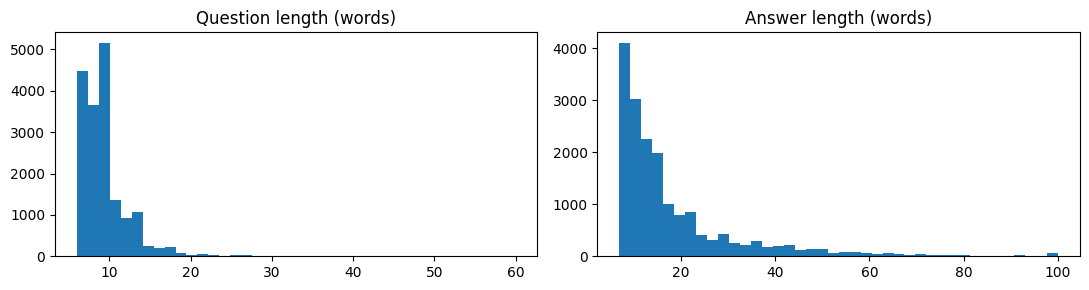

In [ ]:
# ---------------- apply preprocessing ----------------
df = df0.copy()
df["question_raw"] = df["question"]
if STRIP_APPENDED:
    df["question"] = df["question"].apply(clean_question)
if DROP_JUNK_ANSWERS:
    keep = ~junk_flags(df["answer"]).any(axis=1)
    print(f"Dropping {(~keep).sum()} non-informative answers")
    df = df[keep]
df = df[(df["question"].str.len() > 5) & (df["answer"].str.len() > 3)]
df = df.drop_duplicates(subset=["question"]).reset_index(drop=True)
df["style"] = np.where(df["answer"].apply(lambda a: bool(ADVISORY.search(a))), "advisory-log", "free-form")
print("Rows after preprocessing:", len(df), "| style split:", df["style"].value_counts().to_dict())

df["q_words"] = df["question"].str.split().str.len()
df["a_words"] = df["answer"].str.split().str.len()
print(df[["q_words", "a_words"]].describe().round(1))

tok_probe = AutoTokenizer.from_pretrained(BASE_MODEL)
q_tok = [len(x) for x in tok_probe(df["question"].tolist())["input_ids"]]
a_tok = [len(x) for x in tok_probe(text_target=df["answer"].tolist())["input_ids"]]
print(f"\nQuestions longer than MAX_IN={MAX_IN} tokens: {np.mean(np.array(q_tok) > MAX_IN):.2%}")
print(f"Answers   longer than MAX_OUT={MAX_OUT} tokens: {np.mean(np.array(a_tok) > MAX_OUT):.2%}")

ans_norm = df["answer"].str.lower().str.strip(); vc = ans_norm.value_counts()
print(f"Unique answers: {vc.shape[0]} of {len(df)} ({vc.shape[0]/len(df):.1%}) | rows whose exact answer appears more than once: {(ans_norm.map(vc) > 1).mean():.1%}")
print("\nMost common question openings:")
print(df["question"].str.lower().str.split().str[:3].str.join(" ").value_counts().head(8).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].hist(df["q_words"].clip(upper=60), bins=40); ax[0].set_title("Question length (words)")
ax[1].hist(df["a_words"].clip(upper=100), bins=40); ax[1].set_title("Answer length (words)")
plt.tight_layout(); plt.show()

## Part 3. Leakage-safe train / validation / test split

Exact duplicates are already removed, but near-duplicate questions with the same answer can still sit on both sides of a random split and inflate scores (retrieval most of all). We split 88 / 6 / 6, measure the leakage, and build **clean** validation and test sets whose questions are not near-duplicates of any training question and whose answers do not appear verbatim in training.

- **Validation (clean)** is used to compare experiments and pick the final model.
- **Test (clean)** is used **once**, in Part 8.

Train 15508 | Val 1057 | Test 1058
Val: near-duplicate question 220 | answer seen in train 203 | leaky overall 342 (32.4%)
Test: near-duplicate question 241 | answer seen in train 203 | leaky overall 359 (33.9%)


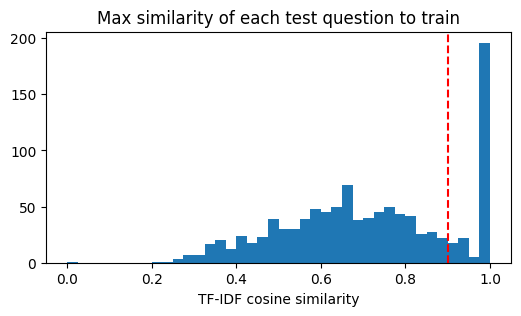

Clean val 715 (experiments use a fixed subset of 300) | Clean test 699 (all used in Part 8)


In [ ]:
work = df[["question", "answer", "style"]]
train_df, tmp = train_test_split(work, test_size=0.12, random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.5, random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

# retrieval index over TRAIN questions only (also used as baseline and as the out-of-domain gate)
tfidf  = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), max_features=20000)
tr_mat = tfidf.fit_transform(train_df["question"])
norm = lambda s: s.str.lower().str.strip()
train_ans_set = set(norm(train_df["answer"]))

def leak_flags(part):
    sim = cosine_similarity(tfidf.transform(part["question"]), tr_mat).max(axis=1)
    ans_seen = norm(part["answer"]).isin(train_ans_set).values
    return sim, ans_seen, (sim >= NEAR_DUP_THRESHOLD) | ans_seen

v_sim, v_ans, v_leaky = leak_flags(val_df)
t_sim, t_ans, t_leaky = leak_flags(test_df)
print(f"Train {len(train_df)} | Val {len(val_df)} | Test {len(test_df)}")
for nm, sim, ans, lk in [("Val", v_sim, v_ans, v_leaky), ("Test", t_sim, t_ans, t_leaky)]:
    print(f"{nm}: near-duplicate question {(sim >= NEAR_DUP_THRESHOLD).sum()} | answer seen in train {ans.sum()} | leaky overall {lk.sum()} ({lk.mean():.1%})")

plt.figure(figsize=(6, 3)); plt.hist(t_sim, bins=40)
plt.axvline(NEAR_DUP_THRESHOLD, color="red", ls="--"); plt.title("Max similarity of each test question to train")
plt.xlabel("TF-IDF cosine similarity"); plt.show()

val_clean,  val_leaky  = val_df[~v_leaky].reset_index(drop=True),  val_df[v_leaky].reset_index(drop=True)
test_clean, test_leaky = test_df[~t_leaky].reset_index(drop=True), test_df[t_leaky].reset_index(drop=True)
val_eval = val_clean.sample(n=min(VAL_EVAL_N, len(val_clean)), random_state=0).reset_index(drop=True)
val_refs, test_refs = val_eval["answer"].tolist(), test_clean["answer"].tolist()
print(f"Clean val {len(val_clean)} (experiments use a fixed subset of {len(val_eval)}) | Clean test {len(test_clean)} (all used in Part 8)")

## Part 4. Metrics and baselines

In [ ]:
rs = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)

def rouge_per_example(preds, refs):
    r1, r2, rl = [], [], []
    for p, r in zip(preds, refs):
        s = rs.score(r, p)
        r1.append(s["rouge1"].fmeasure); r2.append(s["rouge2"].fmeasure); rl.append(s["rougeL"].fmeasure)
    return np.array(r1), np.array(r2), np.array(rl)

# Dose-number F1: for references that contain numbers, do the predicted numbers match? (advice with a wrong dose is unsafe)
NUM = re.compile(r"\d+(?:\.\d+)?")
def num_f1(pred, ref):
    rn, pn = set(NUM.findall(ref)), set(NUM.findall(pred))
    if not rn: return np.nan
    tp = len(rn & pn)
    if tp == 0: return 0.0
    p, r = tp / len(pn), tp / len(rn)
    return 2 * p * r / (p + r)

def boot_ci(x, n=2000, seed=0):
    x = np.asarray(x, dtype=float); rng = np.random.RandomState(seed)
    m = x[rng.randint(0, len(x), (n, len(x)))].mean(axis=1)
    return np.percentile(m, [2.5, 97.5])

def paired_boot(a, b, n=5000, seed=0):
    d = np.asarray(a) - np.asarray(b); rng = np.random.RandomState(seed)
    m = d[rng.randint(0, len(d), (n, len(d)))].mean(axis=1)
    lo, hi = np.percentile(m, [2.5, 97.5]); return d.mean(), lo, hi

store, test_store = {}, {}      # name -> dict(preds, r1, r2, rl, nf, notes) ; validation / test
saved_models, hparams, loss_logs = {}, {}, {}

def score(name, preds, refs, st, notes=""):
    r1, r2, rl = rouge_per_example(preds, refs)
    nf = np.array([num_f1(p, r) for p, r in zip(preds, refs)])
    st[name] = dict(preds=list(preds), r1=r1, r2=r2, rl=rl, nf=nf, notes=notes)
    lo, hi = boot_ci(rl)
    print(f"{name}: ROUGE-1 {r1.mean():.3f} | ROUGE-2 {r2.mean():.3f} | ROUGE-L {rl.mean():.3f} [{lo:.3f}, {hi:.3f}] | dose-num F1 {np.nanmean(nf):.3f}")

def tfidf_preds(questions):
    sims = cosine_similarity(tfidf.transform(list(questions)), tr_mat)
    return train_df["answer"].iloc[sims.argmax(axis=1)].tolist()

In [ ]:
# E0a: random training answer (performance floor)
rng = np.random.RandomState(SEED)
score("E0a Random train answer", train_df["answer"].iloc[rng.randint(0, len(train_df), len(val_eval))].tolist(), val_refs, store, "floor")
# E0b: TF-IDF nearest-question retrieval (main baseline)
score("E0b TF-IDF retrieval (baseline)", tfidf_preds(val_eval["question"]), val_refs, store, "nearest train question -> its answer")

# How much would leakage have inflated the baseline?
def tfidf_rl(part):
    return rouge_per_example(tfidf_preds(part["question"]), part["answer"].tolist())[2].mean()
print(f"\nTF-IDF ROUGE-L on CLEAN val rows: {tfidf_rl(val_clean):.3f}")
if len(val_leaky): print(f"TF-IDF ROUGE-L on LEAKY val rows: {tfidf_rl(val_leaky):.3f}  <- why the clean split matters")

E0a Random train answer: ROUGE-1 0.111 | ROUGE-2 0.020 | ROUGE-L 0.099 [0.089, 0.111] | dose-num F1 0.097
E0b TF-IDF retrieval (baseline): ROUGE-1 0.323 | ROUGE-2 0.163 | ROUGE-L 0.292 [0.266, 0.318] | dose-num F1 0.329

TF-IDF ROUGE-L on CLEAN val rows: 0.294
TF-IDF ROUGE-L on LEAKY val rows: 0.551  <- why the clean split matters


**Why these metrics?** Answers are free-form advisory sentences, so there is no single correct string.
- **ROUGE-1/2/L** measure word, bigram and longest-common-subsequence overlap with the reference. ROUGE-L suits short ordered advice such as *spray X @ 2 ml per litre*. Every score is reported with a bootstrap 95% confidence interval, and model comparisons use a paired bootstrap, because differences of about 0.01 are within noise on a few hundred examples.
- **BERTScore** compares contextual embeddings, so it credits paraphrases. It is reported with baseline rescaling (roberta-large), so the random-answer floor sits near zero and values are only meaningful relatively.
- **Dose-number F1** checks whether the numbers in the prediction match the numbers in the reference. Overlap metrics cannot see a wrong dose, which is the safety-relevant error here.
- **Exact match** is not used: a generative model rarely reproduces a reference word for word.
- **Manual labelling** of about 60 predictions (Part 9) is still needed, because no automatic metric tells whether the recommended chemical is right for the problem.

## Part 5. Model and experiment runner

**Model.** Flan-T5 is a T5 (v1.1 style) *encoder-decoder Transformer* that was instruction-tuned on a large mixture of tasks. All tasks are cast as *text to text*: the encoder reads `question: <text>` (SentencePiece subword tokens, relative position biases, self-attention), and the decoder generates the answer token by token with cross-attention over the encoder states. Training minimises token-level cross-entropy between the decoder output and the reference answer (teacher forcing). At inference we decode with beam search.

**Why this choice.** (1) The answers are free-form advice, not spans in a passage, so an extractive reader does not fit. (2) Flan-T5 is already instruction-tuned, so it fine-tunes well from a few thousand examples. (3) base (about 250M parameters) trains in fp32 on a free T4; small and large (with LoRA) give a size comparison. (4) A TF-IDF nearest-question retriever is the simple baseline, since the data is highly templated.

**Key hyperparameters** (printed in the table below): learning rate, epochs, effective batch size 16 (8 x 2 accumulation), linear decay with 5% warmup, weight decay 0.01, AdamW, max 128 input / 128 output tokens, fp32 on T4.

In [ ]:
_sig = inspect.signature(Seq2SeqTrainingArguments.__init__).parameters
EVAL_KEY = "eval_strategy" if "eval_strategy" in _sig else "evaluation_strategy"
_has_processing_class = "processing_class" in inspect.signature(Seq2SeqTrainer.__init__).parameters

def make_inputs(questions, prefix="question: "):
    return [prefix + q for q in questions]

def tokenize_pairs(tok, inputs, answers, max_in):
    ds = Dataset.from_dict({"inp": list(inputs), "ans": list(answers)})
    def prep(ex):
        enc = tok(ex["inp"], max_length=max_in, truncation=True)
        enc["labels"] = tok(text_target=ex["ans"], max_length=MAX_OUT, truncation=True)["input_ids"]
        return enc
    return ds.map(prep, batched=True, remove_columns=["inp", "ans"])

@torch.no_grad()
def generate(model, tok, inputs, max_in=MAX_IN, bs=32, num_beams=4, no_repeat=3, with_conf=False):
    # with_conf=True also returns a length-normalised log-probability per answer (needs num_beams >= 2)
    model.eval(); outs, confs = [], []
    if with_conf: num_beams = max(2, num_beams)
    for i in range(0, len(inputs), bs):
        b = tok(inputs[i:i + bs], return_tensors="pt", padding=True, truncation=True, max_length=max_in).to(model.device)
        kw = dict(max_new_tokens=MAX_OUT, num_beams=num_beams, no_repeat_ngram_size=no_repeat)
        if num_beams > 1: kw["early_stopping"] = True
        if with_conf: kw.update(output_scores=True, return_dict_in_generate=True)
        g = model.generate(**b, **kw)
        seqs = g.sequences if with_conf else g
        outs += tok.batch_decode(seqs, skip_special_tokens=True)
        if with_conf: confs += g.sequences_scores.float().cpu().tolist()
    return (outs, confs) if with_conf else outs

def run_experiment(name, model_name, train_inputs, train_answers, eval_inputs, eval_refs, monitor=None,
                   lr=3e-4, epochs=3, n_train=None, batch=8, accum=2, max_in=MAX_IN, seed=SEED,
                   save_dir=None, lora=False, notes=""):
    t0 = time.time(); set_seed(seed)
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
    train_inputs, train_answers = list(train_inputs), list(train_answers)
    if n_train and n_train < len(train_inputs):
        idx = np.random.RandomState(seed).choice(len(train_inputs), n_train, replace=False)
        train_inputs, train_answers = [train_inputs[i] for i in idx], [train_answers[i] for i in idx]

    final_loss = None
    if epochs > 0:
        if lora:
            from peft import LoraConfig, get_peft_model, TaskType
            model = get_peft_model(model, LoraConfig(task_type=TaskType.SEQ_2_SEQ_LM, r=16, lora_alpha=32,
                                                     lora_dropout=0.05, target_modules=["q", "v"]))
            model.print_trainable_parameters()
        ds = tokenize_pairs(tok, train_inputs, train_answers, max_in)
        val_ds = tokenize_pairs(tok, monitor[0], monitor[1], max_in) if monitor else None
        total_steps = int(np.ceil(len(ds) / (batch * accum))) * epochs
        args = Seq2SeqTrainingArguments(
            output_dir="./runs/" + name.split()[0], per_device_train_batch_size=batch, per_device_eval_batch_size=32,
            gradient_accumulation_steps=accum, num_train_epochs=epochs, learning_rate=lr,
            warmup_steps=int(0.05 * total_steps), weight_decay=0.01, lr_scheduler_type="linear",
            logging_steps=50, save_strategy="no", bf16=USE_BF16, fp16=False, optim="adamw_torch",
            max_grad_norm=1.0, report_to="none", seed=seed, label_names=["labels"],
            **{EVAL_KEY: "epoch" if monitor else "no"})
        kw = dict(model=model, args=args, train_dataset=ds,
                  data_collator=DataCollatorForSeq2Seq(tok, model=None if lora else model))
        if val_ds is not None: kw["eval_dataset"] = val_ds
        kw["processing_class" if _has_processing_class else "tokenizer"] = tok
        trainer = Seq2SeqTrainer(**kw)
        final_loss = trainer.train().training_loss
        loss_logs[name] = {"train": [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h],
                           "val":   [(h["step"], h["eval_loss"]) for h in trainer.state.log_history if "eval_loss" in h]}
        if lora: model = model.merge_and_unload()
        if save_dir:
            model.save_pretrained(save_dir); tok.save_pretrained(save_dir)
            saved_models[name] = save_dir; print("Saved model to", save_dir)

    model.to(DEVICE)
    preds = generate(model, tok, eval_inputs, max_in=max_in)
    mins = (time.time() - t0) / 60
    hparams[name] = dict(model=model_name, lr=lr if epochs else None, epochs=epochs, n_train=len(train_inputs) if epochs else 0,
                         eff_batch=batch * accum if epochs else None, max_in=max_in, seed=seed, lora=lora, minutes=round(mins, 1))
    info = f"{model_name}; lr={lr}; epochs={epochs}; n_train={len(train_inputs)}; seed={seed}; {mins:.0f} min"
    if final_loss is not None: info += f"; mean train loss {final_loss:.2f}"
    score(name, preds, eval_refs, store, (info + ". " + notes).strip())
    del model; gc.collect(); torch.cuda.empty_cache()

tr_in, tr_ans = make_inputs(train_df["question"]), train_df["answer"].tolist()
ev_in = make_inputs(val_eval["question"])
mon   = (make_inputs(val_df["question"]), val_df["answer"].tolist())   # validation loss is logged each epoch

# show the architecture facts for the report (printed from the real config)
_cfg = AutoModelForSeq2SeqLM.from_pretrained(BASE_MODEL)
c = _cfg.config
print(f"{BASE_MODEL}: {sum(p.numel() for p in _cfg.parameters())/1e6:.0f}M params | encoder layers {c.num_layers} | decoder layers {c.num_decoder_layers} | d_model {c.d_model} | heads {c.num_heads} | d_ff {c.d_ff} | vocab {c.vocab_size}")
del _cfg; gc.collect()

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

google/flan-t5-base: 248M params | encoder layers 12 | decoder layers 12 | d_model 768 | heads 12 | d_ff 2048 | vocab 32128


7478

## Part 6. Experiments (all scored on the clean *validation* subset)

### E1. Zero-shot Flan-T5-base (two prompts)
**Question:** how much does domain fine-tuning add over an instruction-tuned model that has never seen this data? We try the training prompt and a plain instruction, so the baseline is not weak just because of a poor prompt.

In [ ]:
run_experiment("E1a flan-t5-base zero-shot ('question:' prompt)", BASE_MODEL, tr_in, tr_ans, ev_in, val_refs, epochs=0, notes="no fine-tuning")
run_experiment("E1b flan-t5-base zero-shot (instruction prompt)", BASE_MODEL, tr_in, tr_ans,
               make_inputs(val_eval["question"], "Answer this agriculture question briefly: "), val_refs, epochs=0, notes="no fine-tuning")

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


E1a flan-t5-base zero-shot ('question:' prompt): ROUGE-1 0.113 | ROUGE-2 0.027 | ROUGE-L 0.098 [0.086, 0.110] | dose-num F1 0.015


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


E1b flan-t5-base zero-shot (instruction prompt): ROUGE-1 0.105 | ROUGE-2 0.033 | ROUGE-L 0.092 [0.078, 0.107] | dose-num F1 0.015


### E2. Low learning rate (original v1 setting)
**Question:** what did the original setup (lr 3e-5, 8,000 examples, 3 epochs) achieve? Reference for E3.

In [ ]:
run_experiment("E2 base lr=3e-5, 8k, 3ep", BASE_MODEL, tr_in, tr_ans, ev_in, val_refs, monitor=mon, lr=3e-5, epochs=3, n_train=8000)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1057 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss
1,5.641273,2.522228
2,5.178123,2.379075
3,5.111173,2.343497


E2 base lr=3e-5, 8k, 3ep: ROUGE-1 0.305 | ROUGE-2 0.134 | ROUGE-L 0.279 [0.259, 0.298] | dose-num F1 0.252


### E3. Higher learning rate
**Hypothesis:** E2 is underfit (T5 is usually fine-tuned at 1e-4 to 3e-4). Only the learning rate changes versus E2.

In [ ]:
run_experiment("E3 base lr=3e-4, 8k, 3ep", BASE_MODEL, tr_in, tr_ans, ev_in, val_refs, monitor=mon, lr=3e-4, epochs=3, n_train=8000)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1057 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss
1,4.438123,1.980352
2,3.733192,1.821224
3,3.442040,1.781803


E3 base lr=3e-4, 8k, 3ep: ROUGE-1 0.358 | ROUGE-2 0.189 | ROUGE-L 0.329 [0.306, 0.352] | dose-num F1 0.303


### E4a / E4. More data, then more epochs (two separate changes)
**Question:** does going from 8k to all ~17.7k examples help (E3 -> E4a), and do 5 epochs beat 3 (E4a -> E4)? E4 is the candidate final model and is saved.

In [ ]:
run_experiment("E4a base lr=3e-4, all data, 3ep", BASE_MODEL, tr_in, tr_ans, ev_in, val_refs, monitor=mon, lr=3e-4, epochs=3)
run_experiment("E4 base lr=3e-4, all data, %dep" % FULL_EPOCHS, BASE_MODEL, tr_in, tr_ans, ev_in, val_refs, monitor=mon,
               lr=3e-4, epochs=FULL_EPOCHS, save_dir="./final_model_e4")

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Map:   0%|          | 0/15508 [00:00<?, ? examples/s]

Map:   0%|          | 0/1057 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss
1,4.039472,1.779888
2,3.377715,1.627475
3,2.982194,1.586889


...

Map:   0%|          | 0/15508 [00:00<?, ? examples/s]

Map:   0%|          | 0/1057 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss
1,4.055597,1.787301
2,3.367824,1.617534
3,2.899936,1.532549
4,2.668816,1.499372
5,2.541048,1.504106


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model to ./final_model_e4
E4 base lr=3e-4, all data, 5ep: ROUGE-1 0.396 | ROUGE-2 0.222 | ROUGE-L 0.365 [0.341, 0.390] | dose-num F1 0.341


### E5. Smaller model (Flan-T5-small, about 77M parameters)
**Question:** is the larger model worth its cost? Same data and epochs as E4.

In [ ]:
run_experiment("E5 small lr=3e-4, all data, %dep" % FULL_EPOCHS, SMALL_MODEL, tr_in, tr_ans, ev_in, val_refs, monitor=mon,
               lr=3e-4, epochs=FULL_EPOCHS, batch=16, accum=1)

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  308MB            

...

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Map:   0%|          | 0/15508 [00:00<?, ? examples/s]

Map:   0%|          | 0/1057 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss
1,2.424032,2.152025
2,2.125322,1.957407
3,1.924194,1.865324
4,1.870168,1.813376
5,1.842533,1.802239


E5 small lr=3e-4, all data, 5ep: ROUGE-1 0.357 | ROUGE-2 0.189 | ROUGE-L 0.330 [0.306, 0.355] | dose-num F1 0.305


### E6. Retrieval-augmented hybrid
**Question:** can combining retrieval and generation beat either alone? The input is `question + answer of the nearest *other* training question`. For training rows we exclude the row itself **and** neighbours above the near-duplicate threshold, so the model sees retrievals as noisy as those it gets on clean evaluation data (otherwise it learns to copy the context). Compare E6 with **E3** (same 8k / 3 epoch budget).

In [ ]:
def nearest_answers(queries, exclude_self=False, cap=None, chunk=1000):
    Q = tfidf.transform(list(queries)); out = []
    for s in range(0, Q.shape[0], chunk):
        sims = cosine_similarity(Q[s:s + chunk], tr_mat)
        if exclude_self: sims[np.arange(sims.shape[0]), np.arange(s, s + sims.shape[0])] = -1
        if cap is not None: sims[sims >= cap] = -1
        out += train_df["answer"].iloc[sims.argmax(axis=1)].tolist()
    return out

rag_in = lambda qs, ctx: [f"question: {q} context: {c}" for q, c in zip(qs, ctx)]
tr_rag  = rag_in(train_df["question"], nearest_answers(train_df["question"], exclude_self=True, cap=NEAR_DUP_THRESHOLD))
ev_rag  = rag_in(val_eval["question"], nearest_answers(val_eval["question"]))
mon_rag = (rag_in(val_df["question"], nearest_answers(val_df["question"], cap=NEAR_DUP_THRESHOLD)), val_df["answer"].tolist())
print(ev_rag[0][:300])
run_experiment("E6 base + retrieval (RAG), 8k, 3ep", BASE_MODEL, tr_rag, tr_ans, ev_rag, val_refs, monitor=mon_rag,
               lr=3e-4, epochs=3, n_train=8000, max_in=256, notes="nearest-neighbour answer appended as context")

question: asking about the control of yellow stem borer and blb in rice context: date 06-09-2019 07-09-2019 08-09-2019 09-09-2019 10-09-2019 total / average rainfall (mm) 28.1 21.3 25.0 22.4 31.6 128.4 max. temp. (?) 32.9 32.7 32.1 32.0 32.1 32.4 min. temp. (?) 23.2 23.1 23.0 23.0 23.8 23.2


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1057 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss
1,4.109277,1.854825
2,3.454386,1.719722
3,3.169549,1.697741


E6 base + retrieval (RAG), 8k, 3ep: ROUGE-1 0.379 | ROUGE-2 0.208 | ROUGE-L 0.352 [0.326, 0.376] | dose-num F1 0.333


### E7. Decoding ablation (no retraining)
**Question:** `no_repeat_ngram_size=3` could block legitimately repeated n-grams in templated answers ("per bigha ... per bigha"). Does beam width or that constraint matter? Uses the saved E4 model.

In [ ]:
e4_dir = saved_models[[n for n in saved_models if n.startswith("E4 ")][0]]
_tok = AutoTokenizer.from_pretrained(e4_dir); _m = AutoModelForSeq2SeqLM.from_pretrained(e4_dir).to(DEVICE)
for nm, kw in [("E7a decode: greedy", dict(num_beams=1, no_repeat=3)),
               ("E7b decode: beam4, no n-gram block", dict(num_beams=4, no_repeat=0)),
               ("E7c decode: beam8", dict(num_beams=8, no_repeat=3))]:
    score(nm, generate(_m, _tok, ev_in, **kw), val_refs, store, f"E4 model; {kw}")
del _m; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


E7a decode: greedy: ROUGE-1 0.386 | ROUGE-2 0.211 | ROUGE-L 0.354 [0.329, 0.380] | dose-num F1 0.366
E7b decode: beam4, no n-gram block: ROUGE-1 0.394 | ROUGE-2 0.224 | ROUGE-L 0.364 [0.339, 0.389] | dose-num F1 0.347
E7c decode: beam8: ROUGE-1 0.394 | ROUGE-2 0.220 | ROUGE-L 0.362 [0.338, 0.387] | dose-num F1 0.349


## Part 7. Validation results

,experiment,rouge1,rouge2,rougeL,rougeL_95CI,dose_num_F1
0,E0a Random train answer,0.1108,0.0196,0.0994,"[0.089, 0.111]",0.0966
1,E0b TF-IDF retrieval (baseline),0.3232,0.1630,0.2922,"[0.266, 0.318]",0.3288
2,E1a flan-t5-base zero-shot ('question:' prompt),0.1134,0.0269,0.0978,"[0.086, 0.110]",0.0147
3,E1b flan-t5-base zero-shot (instruction prompt),0.1048,0.0333,0.0922,"[0.078, 0.107]",0.0147
4,"E2 base lr=3e-5, 8k, 3ep",0.3050,0.1341,0.2794,"[0.259, 0.298]",0.2520
5,"E3 base lr=3e-4, 8k, 3ep",0.3578,0.1888,0.3293,"[0.306, 0.352]",0.3029
6,"E4a base lr=3e-4, all data, 3ep",0.3783,0.2090,0.3506,"[0.327, 0.375]",0.3130
7,"E4 base lr=3e-4, all data, 5ep",0.3961,0.2218,0.3650,"[0.341, 0.390]",0.3412
8,"E5 small lr=3e-4, all data, 5ep",0.3568,0.1889,0.3301,"[0.306, 0.355]",0.3049
9,"E6 base + retrieval (RAG), 8k, 3ep",0.3795,0.2076,0.3522,"[0.326, 0.376]",0.3329


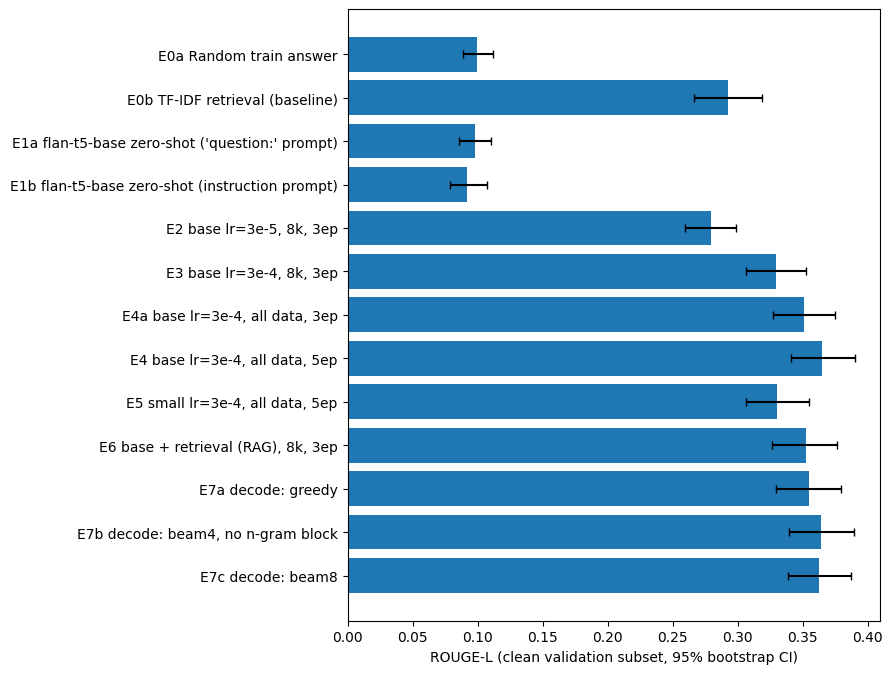

,model,lr,epochs,n_train,eff_batch,max_in,seed,lora,minutes
E1a flan-t5-base zero-shot ('question:' prompt),google/flan-t5-base,None,0,0,None,128,42,False,0.5
E1b flan-t5-base zero-shot (instruction prompt),google/flan-t5-base,None,0,0,None,128,42,False,0.6
"E2 base lr=3e-5, 8k, 3ep",google/flan-t5-base,0.00003,3,8000,16,128,42,False,15.4
"E3 base lr=3e-4, 8k, 3ep",google/flan-t5-base,0.0003,3,8000,16,128,42,False,15.0
"E4a base lr=3e-4, all data, 3ep",google/flan-t5-base,0.0003,3,15508,16,128,42,False,27.3
"E4 base lr=3e-4, all data, 5ep",google/flan-t5-base,0.0003,5,15508,16,128,42,False,45.3
"E5 small lr=3e-4, all data, 5ep",google/flan-t5-small,0.0003,5,15508,16,128,42,False,16.7
"E6 base + retrieval (RAG), 8k, 3ep",google/flan-t5-base,0.0003,3,8000,16,256,42,False,21.0


In [ ]:
def results_df(st):
    rows = []
    for n, v in st.items():
        lo, hi = boot_ci(v["rl"])
        rows.append({"experiment": n, "rouge1": v["r1"].mean(), "rouge2": v["r2"].mean(), "rougeL": v["rl"].mean(),
                     "rougeL_95CI": f"[{lo:.3f}, {hi:.3f}]", "dose_num_F1": np.nanmean(v["nf"]), "notes": v["notes"]})
    return pd.DataFrame(rows)

res_val = results_df(store)
pd.set_option("display.max_colwidth", 80, "display.width", 200)
display(res_val.drop(columns="notes").round(4))
res_val.round(4).to_csv("experiment_results_val.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 0.45 * len(res_val) + 1))
err = [[v["rl"].mean() - boot_ci(v["rl"])[0], boot_ci(v["rl"])[1] - v["rl"].mean()] for v in store.values()]
ax.barh(list(store), [v["rl"].mean() for v in store.values()], xerr=np.array(err).T, capsize=3)
ax.invert_yaxis(); ax.set_xlabel("ROUGE-L (clean validation subset, 95% bootstrap CI)"); plt.tight_layout(); plt.show()

hp = pd.DataFrame(hparams).T; display(hp)   # hyperparameter table for the report
hp.to_csv("hyperparameters.csv")

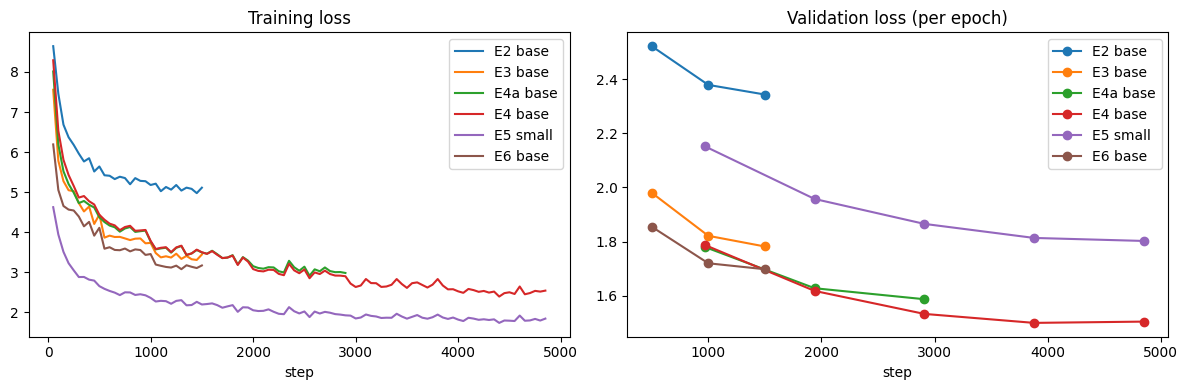

In [ ]:
# Training vs validation loss: under/over-fitting diagnostic
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, log in loss_logs.items():
    short = " ".join(name.split()[:2])
    ax[0].plot(*zip(*log["train"]), label=short)
    if log["val"]: ax[1].plot(*zip(*log["val"]), marker="o", label=short)
ax[0].set_title("Training loss"); ax[1].set_title("Validation loss (per epoch)")
for a in ax: a.set_xlabel("step"); a.legend()
plt.tight_layout(); plt.show()

In [ ]:
# Paired bootstrap: is each difference larger than noise?  (ROUGE-L, per-example)
def find(prefix):
    m = [n for n in store if n.startswith(prefix)]
    return m[0] if m else None

pairs = [("E3", "E2"), ("E4a", "E3"), ("E4 ", "E4a"), ("E4 ", "E5"), ("E6", "E3"), ("E4 ", "E0b"),
         ("E3", "E1a"), ("E7a", "E4 "), ("E7b", "E4 "), ("E7c", "E4 "), ("E8", "E4 ")]
rows = []
for a, b in pairs:
    na, nb = find(a), find(b)
    if na and nb:
        d, lo, hi = paired_boot(store[na]["rl"], store[nb]["rl"])
        rows.append({"A": na, "B": nb, "mean diff (A-B)": round(d, 4), "95% CI": f"[{lo:.3f}, {hi:.3f}]",
                     "significant": "yes" if lo > 0 or hi < 0 else "no"})
display(pd.DataFrame(rows))

,A,B,mean diff (A-B),95% CI,significant
0,"E3 base lr=3e-4, 8k, 3ep","E2 base lr=3e-5, 8k, 3ep",0.0499,"[0.031, 0.069]",yes
1,"E4a base lr=3e-4, all data, 3ep","E3 base lr=3e-4, 8k, 3ep",0.0213,"[0.007, 0.036]",yes
2,"E4 base lr=3e-4, all data, 5ep","E4a base lr=3e-4, all data, 3ep",0.0144,"[0.003, 0.026]",yes
3,"E4 base lr=3e-4, all data, 5ep","E5 small lr=3e-4, all data, 5ep",0.0350,"[0.019, 0.052]",yes
4,"E6 base + retrieval (RAG), 8k, 3ep","E3 base lr=3e-4, 8k, 3ep",0.0229,"[-0.000, 0.046]",no
5,"E4 base lr=3e-4, all data, 5ep",E0b TF-IDF retrieval (baseline),0.0728,"[0.047, 0.099]",yes
6,"E3 base lr=3e-4, 8k, 3ep",E1a flan-t5-base zero-shot ('question:' prompt),0.2315,"[0.205, 0.259]",yes
7,E7a decode: greedy,"E4 base lr=3e-4, all data, 5ep",-0.0106,"[-0.027, 0.004]",no
8,"E7b decode: beam4, no n-gram block","E4 base lr=3e-4, all data, 5ep",-0.0009,"[-0.006, 0.004]",no
9,E7c decode: beam8,"E4 base lr=3e-4, all data, 5ep",-0.0027,"[-0.011, 0.005]",no


In [ ]:
# BERTScore with baseline rescaling (roberta-large on GPU)
from bert_score import score as bscore
def bertscore_f1(preds, refs):
    preds = [p if p.strip() else "." for p in preds]   # bert-score crashes on empty strings (transformers 5.x)
    return bscore(preds, refs, lang="en", model_type="roberta-large", rescale_with_baseline=True,
                  device=DEVICE, batch_size=32, verbose=False)[2].mean().item()

bs = {n: bertscore_f1(v["preds"], val_refs) for n, v in store.items()}
final_val = res_val.assign(bertscore_f1=res_val["experiment"].map(bs)).round(4)
final_val.to_csv("final_results_val.csv", index=False)
display(final_val.drop(columns="notes"))

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,experiment,rouge1,rouge2,rougeL,rougeL_95CI,dose_num_F1,bertscore_f1
0,E0a Random train answer,0.1108,0.0196,0.0994,"[0.089, 0.111]",0.0966,-0.0326
1,E0b TF-IDF retrieval (baseline),0.3232,0.1630,0.2922,"[0.266, 0.318]",0.3288,0.2433
2,E1a flan-t5-base zero-shot ('question:' prompt),0.1134,0.0269,0.0978,"[0.086, 0.110]",0.0147,0.0200
3,E1b flan-t5-base zero-shot (instruction prompt),0.1048,0.0333,0.0922,"[0.078, 0.107]",0.0147,0.0025
4,"E2 base lr=3e-5, 8k, 3ep",0.3050,0.1341,0.2794,"[0.259, 0.298]",0.2520,0.2504
5,"E3 base lr=3e-4, 8k, 3ep",0.3578,0.1888,0.3293,"[0.306, 0.352]",0.3029,0.3004
6,"E4a base lr=3e-4, all data, 3ep",0.3783,0.2090,0.3506,"[0.327, 0.375]",0.3130,0.3135
7,"E4 base lr=3e-4, all data, 5ep",0.3961,0.2218,0.3650,"[0.341, 0.390]",0.3412,0.3341
8,"E5 small lr=3e-4, all data, 5ep",0.3568,0.1889,0.3301,"[0.306, 0.355]",0.3049,0.2986
9,"E6 base + retrieval (RAG), 8k, 3ep",0.3795,0.2076,0.3522,"[0.326, 0.376]",0.3329,0.3194


In [ ]:
for n, v in store.items():
    print(n, "| empty predictions:", sum(1 for p in v["preds"] if not p.strip()))

E0a Random train answer | empty predictions: 0
E0b TF-IDF retrieval (baseline) | empty predictions: 0
E1a flan-t5-base zero-shot ('question:' prompt) | empty predictions: 3
E1b flan-t5-base zero-shot (instruction prompt) | empty predictions: 1
E2 base lr=3e-5, 8k, 3ep | empty predictions: 0
E3 base lr=3e-4, 8k, 3ep | empty predictions: 0
E4a base lr=3e-4, all data, 3ep | empty predictions: 0
E4 base lr=3e-4, all data, 5ep | empty predictions: 0
E5 small lr=3e-4, all data, 5ep | empty predictions: 0
E6 base + retrieval (RAG), 8k, 3ep | empty predictions: 0
E7a decode: greedy | empty predictions: 0
E7b decode: beam4, no n-gram block | empty predictions: 0
E7c decode: beam8 | empty predictions: 0


### Interpretation of validation results

The clean validation results support these conclusions:

- **Best overall validation result:** E4 (Flan-T5-base, learning rate `3e-4`, all 15,508 training examples, 5 epochs) achieved ROUGE-L **0.365** (95% bootstrap CI **0.341–0.390**), BERTScore F1 **0.334**, and dose-number F1 **0.341**. It is the strongest saved generative model in the displayed comparison by ROUGE-L and BERTScore.
- **Fine-tuning matters:** zero-shot Flan-T5-base scored ROUGE-L **0.098** with the `question:` prompt and **0.092** with the instruction prompt. E3, fine-tuned for 3 epochs at `3e-4` on 8,000 examples, reached **0.329** ROUGE-L.
- **Learning rate:** E3 (`3e-4`) outperformed E2 (`3e-5`) by **0.0499 ROUGE-L**, with paired-bootstrap 95% CI **0.031–0.069**; the difference was marked significant by the notebook's paired test. This supports the higher learning rate for this setup.
- **More data and more epochs:** E4a (all data, 3 epochs) improved ROUGE-L by **0.0213** over E3, and E4 (all data, 5 epochs) improved by a further **0.0144** over E4a. Both differences were marked significant in the paired-bootstrap table.
- **Model size:** E4 outperformed Flan-T5-small E5 by **0.0350 ROUGE-L** (95% CI **0.019–0.052**, marked significant). The smaller model trained faster in the recorded runs (about **16.7 min** versus **45.3 min** for E4), so deployment cost and latency remain trade-offs.
- **Retrieval baseline and hybrid:** TF-IDF retrieval reached ROUGE-L **0.292** on clean validation rows. E6 (retrieval-augmented generation) reached **0.352**, but its improvement over E3 was **not significant** in the paired-bootstrap table (difference **0.0229**, CI approximately **0.000–0.046**). The templated answers likely make nearest-neighbour retrieval competitive.
- **Decoding:** beam search with width 4 and no n-gram block reached ROUGE-L **0.364**, compared with **0.354** for greedy decoding. However, the paired comparison with E4 was not significant for either decoding setting; the small numerical differences should not be overstated.
- **Leakage matters:** TF-IDF ROUGE-L was **0.294** on clean validation rows versus **0.551** on leaky rows. This large difference supports the notebook's use of clean validation/test subsets.
- **Important qualification:** these are validation results. The final model should be selected using validation data, then evaluated once on the clean test set in Part 8. ROUGE/BERTScore are similarity measures, not proof of agronomic correctness; manual safety and correctness review remains necessary.


In [ ]:
## Part 8. Final model selection and one-time test evaluation
The final model is chosen **by validation ROUGE-L among the saved models**. It is then evaluated once on the full clean test set (not a sample), together with the baselines.